In [2]:
import pandas as pd 
from matplotlib import pyplot as plt 
import seaborn as sns

df=pd.read_csv('income.csv')
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


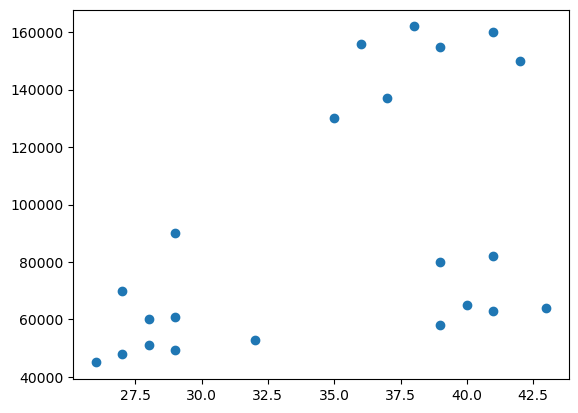

In [3]:
plt.scatter(data=df,x='Age',y='Income($)')

In [7]:
from sklearn.cluster import KMeans

km=KMeans(n_clusters=3,n_init='auto')
km.fit(df.drop('Name',axis=1))
km.labels_ #this is nothing but clusters

C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([2, 2, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1],
      dtype=int32)

In [8]:
df['Cluster']=km.labels_
df.head()

,Name,Age,Income($),Cluster
0,Rob,27,70000,2
1,Michael,29,90000,2
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,0


<Axes: xlabel='Age', ylabel='Income($)'>

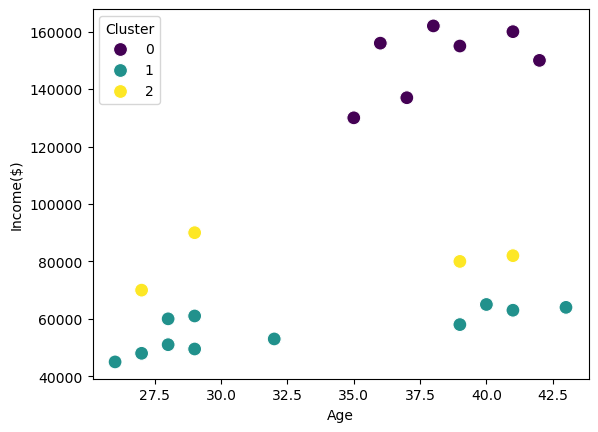

In [9]:
sns.scatterplot(df,x='Age',y='Income($)',palette='viridis',s=100,hue='Cluster')

In [11]:
from sklearn.preprocessing import MinMaxScaler

scaler=MinMaxScaler()
df_scaled=pd.DataFrame(columns=['Age','Income($)'])
df_scaled[['Age','Income($)']]=scaler.fit_transform(df[['Age','Income($)']])
df_scaled.head()

,Age,Income($)
0,0.058824,0.213675
1,0.176471,0.384615
2,0.176471,0.136752
3,0.117647,0.128205
4,0.941176,0.897436


In [12]:
km=KMeans(n_clusters=3,n_init='auto')
km.fit(df_scaled)
km.labels_

C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1],
      dtype=int32)

In [13]:
df_scaled['Cluster']=km.labels_
df_scaled.head()

,Age,Income($),Cluster
0,0.058824,0.213675,0
1,0.176471,0.384615,0
2,0.176471,0.136752,0
3,0.117647,0.128205,0
4,0.941176,0.897436,2


In [15]:
centroids=km.cluster_centers_
centroids

array([[0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ],
       [0.72268908, 0.8974359 ]])

<Axes: xlabel='Age', ylabel='Income($)'>

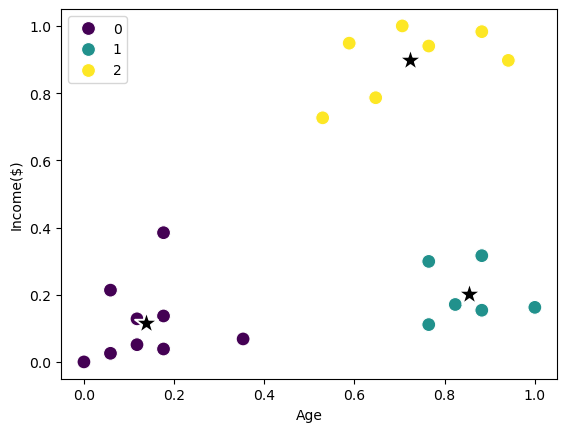

In [19]:
sns.scatterplot(df_scaled,x='Age',y='Income($)',palette='viridis',s=100,hue='Cluster')
sns.scatterplot(x=centroids[:,0],y=centroids[:,1], s=300,marker='*',color='black')

In [22]:
sse=[]

for i in range(1,10):
    km=KMeans(n_clusters=i,n_init='auto')
    km.fit(df_scaled[['Age','Income($)']])
    sse.append(km.inertia_)

sse

C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

[5.434011511988178,
 2.091136388699078,
 0.4750783498553096,
 0.3491047094419566,
 0.3138502783618937,
 0.2551867590573118,
 0.19879303594775455,
 0.14090581089405507,
 0.10824862283029266]

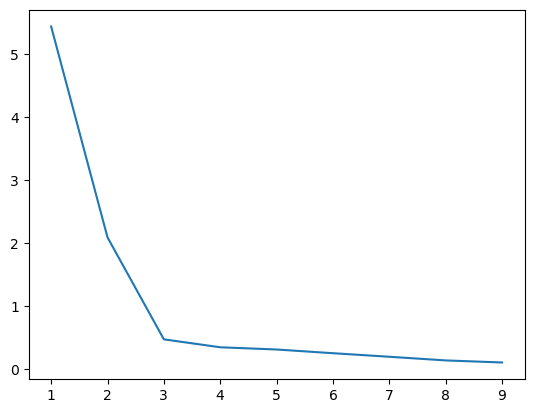

In [24]:
plt.plot(range(1,10),sse)